In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import zipfile
import urllib.request

# Download the dataset
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = urllib.request.urlopen(url)
zip_file = zipfile.ZipFile(io.BytesIO(response.read()))

# Check the filenames inside the ZIP
print("Files available:", zip_file.namelist())


Files available: ['.student.zip_old', 'student.zip']


In [ ]:

# Open the ZIP file inside the downloaded ZIP
inner_zip_data = zip_file.read("student.zip")

inner_zip = zipfile.ZipFile(io.BytesIO(inner_zip_data))

# Display the files inside the inner ZIP
print("Dataset files:", inner_zip.namelist())


Dataset files: ['student-mat.csv', 'student-por.csv', 'student-merge.R', 'student.txt']


In [ ]:

# Load the Mathematics student dataset
df = pd.read_csv(
    inner_zip.open("student-mat.csv"),
    sep=";"
)

# Display the results
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Number of rows and columns: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:

# Display column names and data types
print("DATASET INFORMATION")
df.info()

# Check for missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check for duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# View statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    ob

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


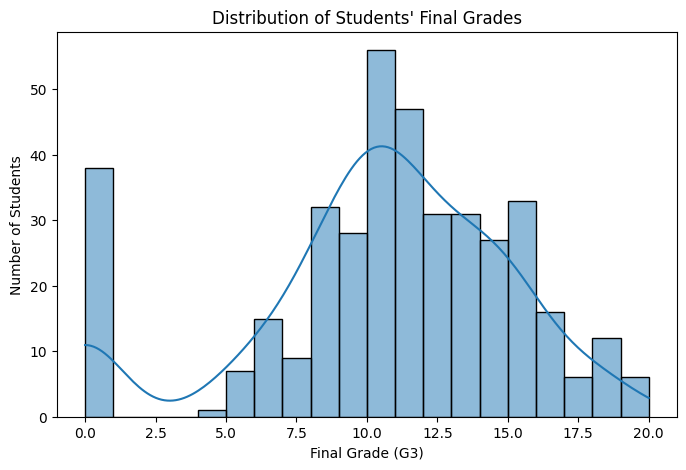

In [ ]:

# Distribution of students' final grades

plt.figure(figsize=(8, 5))
sns.histplot(df["G3"], bins=20, kde=True)

plt.title("Distribution of Students' Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()


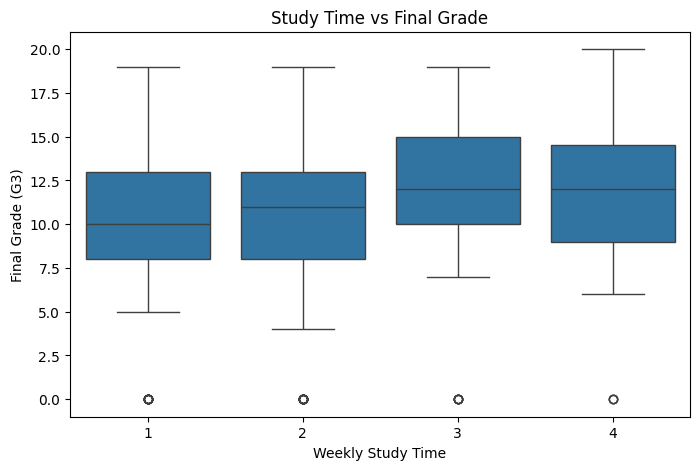

In [ ]:

plt.figure(figsize=(8, 5))

sns.boxplot(x="studytime", y="G3", data=df)

plt.title("Study Time vs Final Grade")
plt.xlabel("Weekly Study Time")
plt.ylabel("Final Grade (G3)")

plt.show()


In [ ]:

# Select the input features and target variable

X = df.drop("G3", axis=1)
y = df["G3"]

# Convert categorical columns into numerical values
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features prepared successfully!")
print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)


Features prepared successfully!
Input features shape: (395, 41)
Target variable shape: (395,)


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("Model trained successfully!")
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Model trained successfully!
Training records: 316
Testing records: 79


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared Score (R2):", round(r2, 2))


MODEL EVALUATION RESULTS
------------------------
Mean Absolute Error (MAE): 1.65
Mean Squared Error (MSE): 5.66
Root Mean Squared Error (RMSE): 2.38
R-squared Score (R2): 0.72


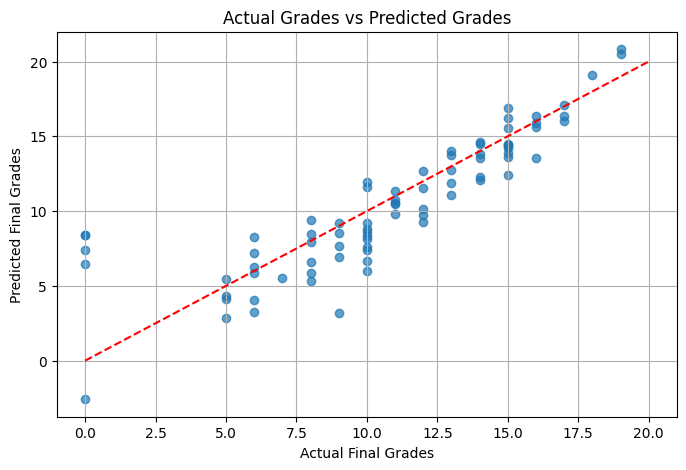

In [ ]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

# Ideal prediction line
plt.plot([0, 20], [0, 20], "r--")

plt.title("Actual Grades vs Predicted Grades")
plt.xlabel("Actual Final Grades")
plt.ylabel("Predicted Final Grades")
plt.grid(True)

plt.show()


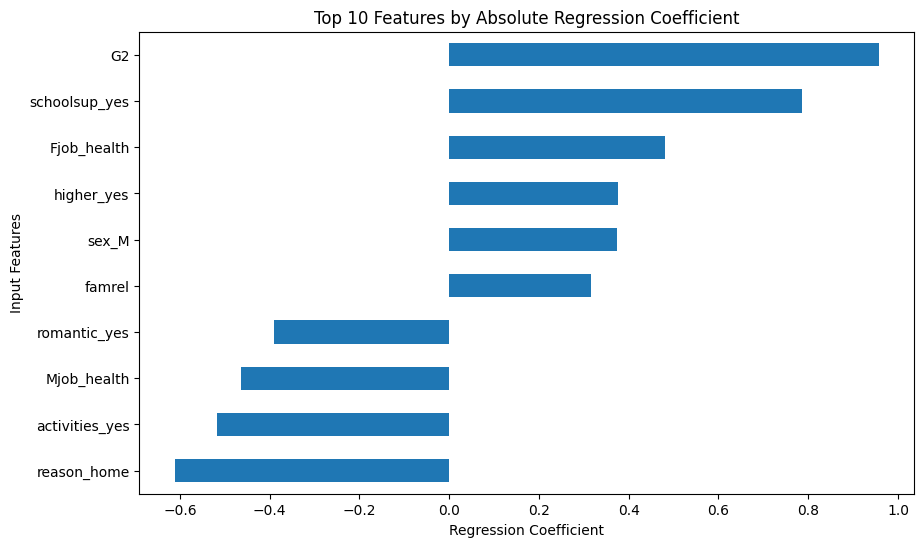

In [ ]:

importance = pd.Series(
    model.coef_,
    index=X.columns
)

importance = importance.reindex(
    importance.abs().sort_values(ascending=False).index
)

plt.figure(figsize=(10, 6))
importance.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Features by Absolute Regression Coefficient")
plt.xlabel("Regression Coefficient")
plt.ylabel("Input Features")

plt.show()
